# State of the art: outcome-testing toolkits, conformal libraries, explainers and fairness libraries

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 to 07 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- name the open toolkits that offer outcome tests, label-free monitoring, conformal prediction, explainers and fairness metrics, say under which licence each can be used by a product of this kind, and say which tests of the ECB instructions none of them implements;
- compare the engine's split-conformal quantile with the rules a reference library applies, and count on a grid how often they return different order statistics;
- check the engine's two-proportion z test and Fisher test against independent identities of SciPy, and its parity difference against the definition of fairlearn's difference;
- say which parts of this notebook were run and which could not be: the packages MAPIE and fairlearn are not in this notebook environment, so their results are not reproduced here.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the packages and print their versions
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.fairness import inference, metrics
from riskvalidation.ml import conformal
from scipy import stats

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

- **The engine's catalogue** of validation tests (`riskvalidation.catalogue()`), to count what the engine implements for machine-learning and fairness validation.
- **The committed calibration size of case C20** (`data/derived/C20/fed-shift.json`): the conformal windows of the Federal Reserve shift variant use a calibration window of 1,471 companies. The notebook uses only that number, and draws random scores of that size.
- **The committed HMDA counts of case C21** (`data/derived/C21/pair-2018-19.json`): the favourable count and the size of each race group of Delaware 2018, to compare the engine's tests of two rates with independent identities.

No new raw data is needed. Both documents are read for their numbers and their baking engine version, printed below.

In [2]:
# Count the engine's ML and fairness tests and read the two committed documents' engine version and sizes
catalogue = rv.catalogue()
by_family = {}
for spec in catalogue:
    by_family[spec.family] = by_family.get(spec.family, 0) + 1
print("tests in the catalogue:", len(catalogue), "| ml:", by_family["ml"], "| fairness:", by_family["fairness"])
fed = json.loads((ROOT / "data" / "derived" / "C20" / "fed-shift.json").read_text(encoding="utf-8"))
hmda = json.loads((ROOT / "data" / "derived" / "C21" / "pair-2018-19.json").read_text(encoding="utf-8"))
print("C20 baked with riskvalidation", fed["provenance"]["riskvalidation_version"], "| C21", hmda["provenance"]["riskvalidation_version"])
n_cal = next(t for t in fed["tests"] if t["test_id"] == "ml.conformal_coverage")["extras"]["n_cal"]
print("committed calibration window:", n_cal)

tests in the catalogue: 129 | ml: 13 | fairness: 12
C20 baked with riskvalidation 0.8.1 | C21 0.8.1
committed calibration window: 1471


## Method

The comparison has two rules. **Reproduce where a pinned reference allows**: an independent implementation, or an identity that holds between two formulas, is run and the difference is reported. **Say what was not run**: a library that is not in the notebook environment is not imported, and its result is not reproduced here, even when the engine's own test suite compares with it.

### The split-conformal quantile against the rule of a reference library

For $n$ calibration scores $s_{(1)} \le \dots \le s_{(n)}$ the exact conformal quantile is the order statistic $s_{(k)}$ with $k = \lceil (n+1)(1-\alpha) \rceil$ (notebook 04). The engine computes $k$ on the exact decimal of $\alpha$. The reference library MAPIE 1.5.0 computes, in its classification quantile (`mapie/utils.py`, `_compute_classification_quantile`, read by the engine's reviewer; the installed package was not run here), the NumPy call

$$\hat q_{\text{MAPIE}} = \texttt{np.quantile}\bigl(s,\; (n+1)(1-\alpha)/n,\; \texttt{method="higher"}\bigr),$$

(the level capped at 1 here), which takes the next order statistic above an interpolation index and can return $s_{(k)}$ or $s_{(k+1)}$. A third rule is the naive float one, $s_{(\lceil (n+1)(1-\alpha) \rceil)}$ with the product taken in floats. The next cell draws random scores of the committed calibration size, applies the three rules at $\alpha = 0.1$ and prints the order statistic each returns; then it scans a grid of calibration sizes $n = 5, \dots, 399$ and $\alpha = 0.01, \dots, 0.99$ and counts the pairs for which each rule differs from the engine.

In [3]:
# The three rules at the committed calibration size, then a grid scan of how often each differs from the engine
rng = np.random.default_rng(3)
scores = np.sort(rng.random(n_cal))
alpha = 0.1
engine_q = conformal.split_conformal_quantile(scores, alpha)
mapie_q = np.quantile(scores, min(1.0, (n_cal + 1) * (1 - alpha) / n_cal), method="higher")
naive_q = scores[math.ceil((n_cal + 1) * (1 - alpha)) - 1]
rank = lambda q: int(np.searchsorted(scores, q)) + 1
print("n_cal", n_cal, "| rank of the engine quantile", rank(engine_q), "| rank under the MAPIE rule", rank(mapie_q), "| rank under the naive float rule", rank(naive_q))
differ_mapie = differ_naive = total = 0
for n in range(5, 400):
    s = np.sort(rng.random(n))
    for a in np.arange(1, 100) / 100:
        total += 1
        engine = conformal.split_conformal_quantile(s, float(a))
        if math.isinf(engine):
            continue
        differ_mapie += int(np.quantile(s, min(1.0, (n + 1) * (1 - a) / n), method="higher") != engine)
        differ_naive += int(s[min(math.ceil((n + 1) * (1 - a)), n) - 1] != engine)
print("pairs (n, alpha) scanned:", total, "| MAPIE rule differs from the engine:", differ_mapie, "| naive float rule differs:", differ_naive)

n_cal 1471 | rank of the engine quantile 1325 | rank under the MAPIE rule 1325 | rank under the naive float rule 1325
pairs (n, alpha) scanned: 39105 | MAPIE rule differs from the engine: 19525 | naive float rule differs: 231


## State of the art

### What exists, and under which licence

The research dossier on model risk (verified on 2026-10-04 on the GitHub and PyPI records; licences read from the licence files, not legal advice) finds these open tools. The column "usable" says whether a product under a permissive licence can **depend** on the package; AGPL, GPL and BSL tools are cited and compared, never imported.

| Tool | What it offers (outcome and model tests) | Licence | Usable as a dependency |
|---|---|---|---|
| PiML-Toolbox (Wells Fargo origin) | accuracy, explainability (PFI, PDP, ALE, SHAP), WeakSpot, Overfit, Reliability (split conformal), Robustness, Resilience | Apache-2.0 | licence yes; frozen since 2025 and shipped as binary wheels, so only as a cross-check |
| ValidMind library | data and model validation tests, ongoing monitoring, documentation | AGPL-3.0 or commercial | no |
| BBVA mercury-robust | data and model test suites: drift, label leaking, cohort performance | Apache-2.0 | yes |
| ING probatus | SHAP-based interpretation, `sample_similarity` (resemblance model) | MIT | yes |
| ING popmon, Evidently | population shift monitoring, drift tests (KS, chi-square, PSI) and data quality | MIT, Apache-2.0 | yes |
| NannyML | confidence-based performance estimation (CBPE), drift | Apache-2.0 | yes, with a maintenance caveat |
| MAPIE | conformal prediction (split, CV+, jackknife+, conformalized quantile regression, risk control) | BSD-3-Clause | yes |
| fairlearn | fairness assessment (MetricFrame, parity and equalized-odds differences and ratios) and mitigation | MIT | yes |
| SHAP, InterpretML | Shapley explanations (TreeSHAP), glass-box EBM | MIT | yes (the pipeline uses SHAP; the engine never imports it) |
| deepchecks, alibi, dalex | validation suites and explainers | AGPL-3.0, BSL 1.1, GPL-3.0 | no |

The dossier's finding that matters for the engine: **no toolkit found implements the ECB Jeffreys, MWB, migration z-tests, HHI-CV test or generalised AUC exactly as specified** (these belong to the credit-risk topics of this set), and none of the toolkits above reports the **size and the power** of its tests. The conformal ideas the dossier lists beyond the split form (conformalized quantile regression, jackknife+, Venn-Abers calibrated probabilities) are in the literature and in MAPIE; the engine implements the split form.

### What the engine implements, by comparison

The engine's catalogue (cell above) holds the tests of this topic: ML (robustness, resilience, seeds, reason codes, explainer agreement, additivity, overfit, weak spots, conformal coverage, leakage, data quality, the CBPE estimate and the challenger Brier) and fairness (selection rates, parity, adverse impact, the two-rate tests, equalized odds, equal opportunity, calibration and AUC by group, conditional disparity, rate spread, replication, situation testing). What it adds to a toolkit is the way each is stated: a null hypothesis, an engine policy with a light, a null law that takes the calibration size into account (notebook 04) and an exact permutation reference (notebook 02). The next cells reproduce the part of that comparison that the notebook environment can run.

### The two-rate tests against independent identities

For two groups with $x_1$ of $n_1$ and $x_2$ of $n_2$, the squared pooled z statistic equals Pearson's chi-square statistic of the $2 \times 2$ table **without continuity correction**, and its p-value equals that of the chi-square test with one degree of freedom. Fisher's exact test is the hypergeometric test of SciPy's `fisher_exact`. The next cell checks both identities on the five contrasts of the committed HMDA race attribute, and the parity difference against the definition used by fairlearn's `demographic_parity_difference` for two groups, the largest minus the smallest selection rate.

In [4]:
# Check the z test against Pearson chi-square, Fisher against SciPy, and the parity difference against max minus min of the selection rates
race = hmda["outputs"]["attributes"][0]
groups = {g["group"]: (g["n_approved"], g["n"]) for g in race["groups"]}
x_ref, n_ref = groups[race["reference_group"]]
print(f'{"group":44s} {"z²":>10s} {"chi-square":>11s} {"p z":>10s} {"p chi-square":>15s} {"p Fisher, engine":>19s} {"p Fisher, SciPy":>18s}')
for name, (x, n) in groups.items():
    if name == race["reference_group"]:
        continue
    z = inference.two_proportion_z_test(x, n, x_ref, n_ref)
    table = [[x, n - x], [x_ref, n_ref - x_ref]]
    chi2, p_chi2, _, _ = stats.chi2_contingency(table, correction=False)
    fisher = inference.fisher_exact_test(x, n, x_ref, n_ref)
    p_scipy = stats.fisher_exact(table).pvalue
    print(f"{name:44s} {z.statistic ** 2:10.3f} {chi2:11.3f} {z.p_value:10.3e} {p_chi2:15.3e} {fisher.p_value:19.3e} {p_scipy:18.3e}")
rates = metrics.group_selection_rates(np.r_[np.ones(60), np.zeros(40), np.ones(75), np.zeros(25)].astype(int), np.r_[np.repeat("A", 100), np.repeat("B", 100)])
spread = max(r.rate for r in rates.values()) - min(r.rate for r in rates.values())
print("parity difference for two groups, engine:", abs(metrics.demographic_parity_difference(rates, "B")["A"]), "| largest minus smallest rate:", round(spread, 12))

group                                                z²  chi-square        p z    p chi-square    p Fisher, engine    p Fisher, SciPy
American Indian or Alaska Native                 55.357      55.357  1.005e-13       1.005e-13           1.208e-11          1.208e-11
Asian                                             1.140       1.140  2.857e-01       2.857e-01           2.857e-01          2.857e-01
Black or African American                       581.966     581.966 1.401e-128      1.401e-128          2.998e-120         2.998e-120
Native Hawaiian or Other Pacific Islander        18.503      18.503  1.696e-05       1.696e-05           7.363e-05          7.363e-05
2 or more minority races                         42.695      42.695  6.399e-11       6.399e-11           3.030e-09          3.030e-09
parity difference for two groups, engine: 0.15 | largest minus smallest rate: 0.15


### What could not be run

The engine's own test suite compares the split-conformal quantile with MAPIE and the fairness metrics with fairlearn under its optional `ml` extra (`mapie>=1.5,<2`, `fairlearn>=0.15,<0.16`). Neither package is in the notebook environment (`notebooks/requirements.txt` holds `riskvalidation`, NumPy, SciPy and Matplotlib), so this notebook does not import them and does not reproduce their results: the MAPIE rule above is the NumPy call the engine's review read in MAPIE 1.5.0, not MAPIE running. Running them needs the exact pins `mapie==1.5.0` and `fairlearn==0.15.x` (the patch release to be chosen) added to `notebooks/requirements.txt` and to the SDD technology table, a decision for the maintainers of the notebook environment. The same holds for the NannyML and SHAP libraries: the CBPE formula of the engine is the one the NannyML documentation gives (notebook 04), and the equality of the numbers was not tested here.

### The evidence, drawn

The figure shows the grid of the first cell of the Method: for each calibration size the share of the 99 values of $\alpha$ for which the MAPIE rule and the naive float rule return an order statistic different from the engine's.

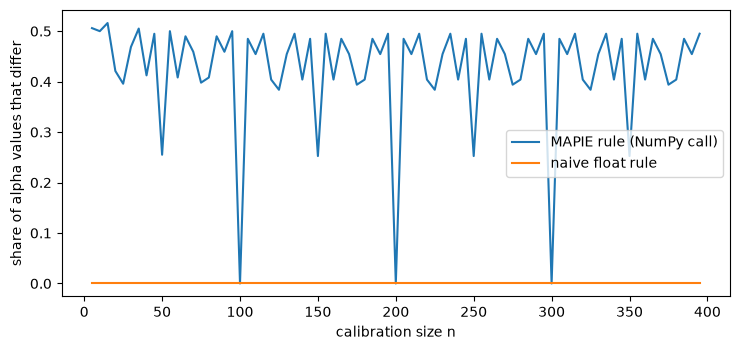

In [5]:
# For each calibration size the share of alpha values at which each rule differs from the engine
sizes = list(range(5, 400, 5))
share_mapie, share_naive = [], []
for n in sizes:
    s = np.sort(rng.random(n))
    alphas = np.arange(1, 100) / 100
    engine = np.array([conformal.split_conformal_quantile(s, float(a)) for a in alphas])
    mapie = np.array([np.quantile(s, min(1.0, (n + 1) * (1 - a) / n), method="higher") for a in alphas])
    naive = np.array([s[min(math.ceil((n + 1) * (1 - a)), n) - 1] for a in alphas])
    finite = np.isfinite(engine)
    share_mapie.append(float(np.mean(mapie[finite] != engine[finite])))
    share_naive.append(float(np.mean(naive[finite] != engine[finite])))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(sizes, share_mapie, label="MAPIE rule (NumPy call)")
ax.plot(sizes, share_naive, label="naive float rule")
ax.set_xlabel("calibration size n")
ax.set_ylabel("share of alpha values that differ")
ax.legend()
fig.tight_layout()
plt.show()

## Results

- **The engine's catalogue holds 129 tests, 13 for machine-learning validation and 12 for fairness.** The dossier's survey of open toolkits finds outcome tests (PiML, mercury-robust, ValidMind), label-free monitoring (NannyML, popmon, Evidently), conformal libraries (MAPIE), explainers (SHAP, InterpretML) and fairness libraries (fairlearn), under licences from MIT to AGPL; the ones under AGPL, GPL and BSL are compared and not imported. None reports the size and the power of its tests, and none implements the ECB credit-risk tests as specified, which is the gap the dossier records and the engine fills for the tests of this topic with a stated null, a policy light and, for two of them, a corrected null law (notebooks 02 and 04).
- **At the committed calibration size the rules agree.** For 1,471 scores at $\alpha = 0.1$ the engine, the NumPy `higher` call attributed to MAPIE and the naive float rule all return the score of rank 1,325, the rank $k$ of the committed C20 windows.
- **Across the grid they do not.** Over 39,105 pairs $(n, \alpha)$ with $n$ from 5 to 399, the NumPy `higher` call returns a different order statistic from the engine's in 19,525 (49.9%): the engine's documentation states that the `higher` method returns the $(k+1)$-th order statistic where the exact rule returns the $k$-th, a more conservative quantile. The naive float rule differs in 231 pairs (0.6%), the floating-point trap of notebook 04. This measures the NumPy call, not the MAPIE package, which was not run: whether MAPIE's code is exactly that call is UNVERIFIED here.
- **The tests of two rates match independent identities.** For the five HMDA race contrasts the squared pooled z statistic equals Pearson's chi-square without continuity correction to the printed digits (for example 581.966 for the Black against the White group), their p-values are equal (1.401e-128), and the engine's Fisher p-values equal SciPy's. The engine's parity difference for two groups, 0.15, equals the largest minus the smallest selection rate, the definition of fairlearn's difference. Both documents were baked with riskvalidation 0.8.1.
- **What was not run.** MAPIE, fairlearn, NannyML and SHAP are not in the notebook environment, so nothing here reproduces their results. The engine's own test suite compares with MAPIE and fairlearn under its `ml` extra; running them here needs `mapie==1.5.0` and `fairlearn==0.15.x` pinned in `notebooks/requirements.txt` and in the SDD technology table, which is a decision for the maintainers of the environment.

What the results do not show: that the engine is better than any of these tools. They show what each does and does not state, and where an independent identity or a NumPy rule can be checked; the licence column is a reading of the dossier and not legal advice.

## Summary

- The open toolkits cover outcome tests, label-free monitoring, conformal prediction, explainers and fairness metrics under licences from MIT to AGPL; none reports the size and power of its tests, and none implements the ECB credit-risk tests as specified.
- The engine holds 13 machine-learning and 12 fairness tests, each with a stated null, a policy light and the convention that sets it.
- The exact conformal rank and the naive float rank agree at the committed calibration size and differ in 0.6% of a grid of 39,105 pairs; the NumPy `higher` call attributed to MAPIE returns a different order statistic in 49.9% of them (the package itself was not run).
- The engine's two-rate tests equal the Pearson chi-square (without continuity correction) and SciPy's Fisher test, and its parity difference equals the largest minus the smallest selection rate.
- MAPIE, fairlearn, NannyML and SHAP are not in the notebook environment; running them needs pinned versions that are a decision for the environment's maintainers.

**What to try next.** Notebook 09 measures, with the engine's own plants, how often these tests fire when nothing is wrong and how often they find what was planted, and shows the corrections of the conformal and shift tests.

## References

- PiML-Toolbox (Apache-2.0), outcome tests WeakSpot, Overfit, Reliability, Robustness and Resilience; Sudjianto et al. (2023), arXiv 2305.04214. https://github.com/SelfExplainML/PiML-Toolbox
- ValidMind library (AGPL-3.0 or commercial licence): data and model validation tests and documentation. https://github.com/validmind/validmind-library
- BBVA mercury-robust (Apache-2.0): data and model test suites, drift and label-leakage checks. https://github.com/BBVA/mercury-robust
- ING (2026), probatus, `sample_similarity`: a resemblance model between two datasets. https://github.com/ing-bank/probatus
- ING popmon (MIT): population shift monitoring. https://github.com/ing-bank/popmon
- Evidently (Apache-2.0): drift, data quality and model quality reports. https://github.com/evidentlyai/evidently
- NannyML (Apache-2.0), the open implementation of CBPE. https://github.com/NannyML/nannyml
- NannyML, how confidence-based performance estimation (CBPE) works. https://nannyml.readthedocs.io/en/stable/how_it_works/performance_estimation.html
- fairlearn (MIT), fairness assessment and mitigation. https://github.com/fairlearn/fairlearn
- MAPIE (BSD-3-Clause), conformal prediction for scikit-learn. https://github.com/scikit-learn-contrib/MAPIE
- SHAP (MIT), the reference implementation of Shapley explanations. https://github.com/shap/shap
- Angelopoulos, A. N. and Bates, S. (2021), A gentle introduction to conformal prediction and distribution-free uncertainty quantification, arXiv 2107.07511. https://arxiv.org/abs/2107.07511
- Romano, Y., Patterson, E. and Candes, E. J. (2019), Conformalized quantile regression, arXiv 1905.03222. https://arxiv.org/abs/1905.03222
- Barber, R. F., Candes, E. J., Ramdas, A. and Tibshirani, R. J. (2021), Predictive inference with the jackknife+, Annals of Statistics 49(1). https://doi.org/10.1214/20-AOS1965
- Vovk, V. and Petej, I. (2012), Venn-Abers predictors, arXiv 1211.0025. https://arxiv.org/abs/1211.0025
- Hardt, M., Price, E. and Srebro, N. (2016), Equality of opportunity in supervised learning, arXiv 1610.02413. https://arxiv.org/abs/1610.02413
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Annex 1 (the AUC and its variance). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- ECB (2025), Guide to internal models, the paragraphs on the randomness of the training process, overfitting, explainability and the justification of complexity (43, 59, 60, 62, 64 to 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- 29 CFR 1607.4(D), Uniform Guidelines on Employee Selection Procedures: the four-fifths rule, an employment benchmark. https://www.law.cornell.edu/cfr/text/29/1607.4